##### Libraries

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import chi2 as chi2_test, mutual_info_classif

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

##### Load Dataset

In [2]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

print("Shape:", df.shape)

Shape: (7043, 21)


In [3]:
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


##### Checking Missing Values and Duplicates

In [5]:
print("Missing values:\n", df.isnull().sum())

Missing values:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [6]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [7]:
# Unique values in each categorical column
for col in df.select_dtypes(include='object').columns:
    if col != 'customerID':
        print(f"{col}: {df[col].unique()}")

gender: ['Female' 'Male']
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
MultipleLines: ['No phone service' 'No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes' 'No internet service']
OnlineBackup: ['Yes' 'No' 'No internet service']
DeviceProtection: ['No' 'Yes' 'No internet service']
TechSupport: ['No' 'Yes' 'No internet service']
StreamingTV: ['No' 'Yes' 'No internet service']
StreamingMovies: ['No' 'Yes' 'No internet service']
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: ['Yes' 'No']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
TotalCharges: ['29.85' '1889.5' '108.15' ... '346.45' '306.6' '6844.5']
Churn: ['No' 'Yes']


##### Our Dataset dont have any missing values or duplicates. So we created some missing values and duplicates

###### We used 300 Duplicates and 157 Missing Values
###### Created another DataFrame called df_noisy and gonna do removing duplicates and missing value operation to that

In [8]:
TARGET_ROWS = 7500
N_DUPLICATES = 300
N_MISSING = 157

rng = np.random.default_rng(42)

# Create Duplicates
duplicates = df.sample(n=N_DUPLICATES, random_state=42)

# Create Missing Values
# Didn't Missed CustomerID and Churn
missing_rows = df.sample(n=N_MISSING, random_state=7).copy()
feature_cols = [c for c in df.columns if c not in ['customerID', 'Churn']]
for idx in missing_rows.index:
    n_blank = rng.integers(1, 4)
    blank_cols = rng.choice(feature_cols, size=n_blank, replace=False)
    missing_rows.loc[idx, blank_cols] = np.nan

# Combine into Dataframe
df_noisy = (pd.concat([df, duplicates, missing_rows])
              .sample(frac=1, random_state=42)
              .reset_index(drop=True))

df_noisy.to_csv('telco_churn_7500.csv', index=False)

print("New shape:", df_noisy.shape)
print("Duplicate rows:", df_noisy.duplicated().sum())
print("Rows with missing values:", df_noisy.isnull().any(axis=1).sum())

New shape: (7500, 21)
Duplicate rows: 300
Rows with missing values: 157


##### Checking Missing Values

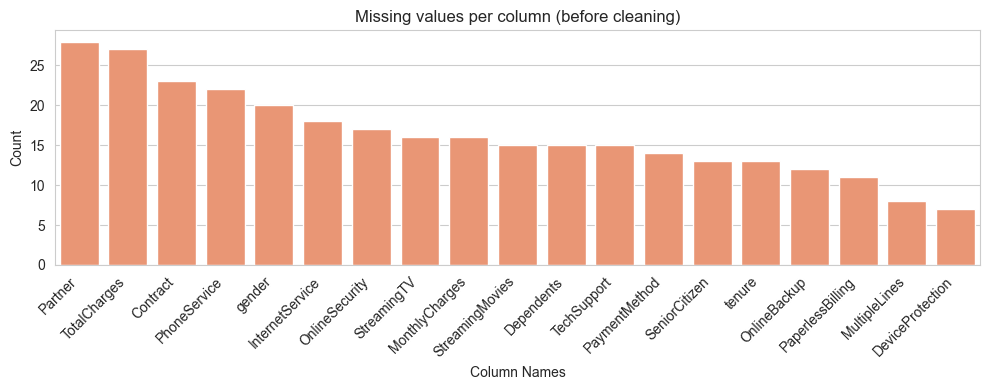

In [9]:
missing = df_noisy.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 4))
sns.barplot(x=missing.index, y=missing.values, color='#fc8d62')
plt.title('Missing values per column (before cleaning)')
plt.xlabel('Column Names')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### Checking Duplicates

In [10]:
duplicates = df_noisy.duplicated()
print(f"Duplicate Rows: {duplicates.sum()}")

Duplicate Rows: 300


##### Remove Duplicates and Missing Value Columns

In [11]:
before = len(df_noisy)
df_noisy = df_noisy.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df_noisy)} duplicate rows -> {df_noisy.shape}")

Removed 300 duplicate rows -> (7200, 21)


In [12]:
before = len(df_noisy)
df_noisy = df_noisy.dropna().reset_index(drop=True)
print(f"Removed {before - len(df_noisy)} rows with missing values -> {df_noisy.shape}")

Removed 157 rows with missing values -> (7043, 21)


In [13]:
print("Final shape:", df_noisy.shape)
print("Remaining duplicates:", df_noisy.duplicated().sum())
print("Remaining missing values:", df_noisy.isnull().sum().sum())
print("Duplicate customerIDs:", df_noisy['customerID'].duplicated().sum())

Final shape: (7043, 21)
Remaining duplicates: 0
Remaining missing values: 0
Duplicate customerIDs: 0


###### Now both datasets are equal. So from now onwards gonna use df instead of df_noisy

In [14]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce').fillna(0)
df = df.drop(columns='customerID')   # Remove ID Column
print(df.shape)

(7043, 20)


##### Ourlier finding

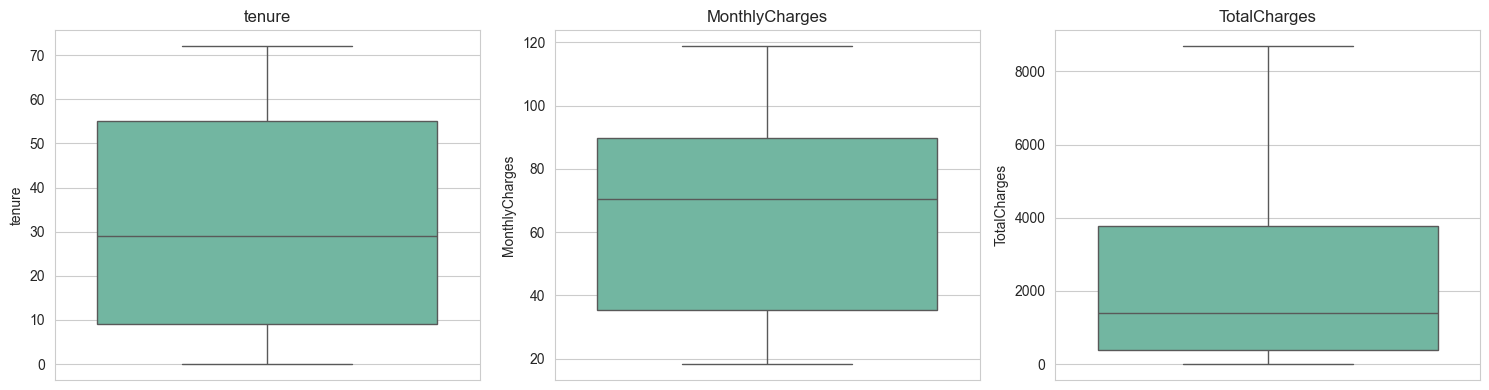

,Feature,IQR lower,IQR upper,IQR outliers,Z-score outliers (|z|>3)
0,tenure,-60.00,124.00,0,0
1,MonthlyCharges,-46.02,171.38,0,0
2,TotalCharges,-4683.52,8868.67,0,0


In [15]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color='#66c2a5')
    ax.set_title(col)
plt.tight_layout()
plt.show()

outlier_summary = []
for col in num_cols:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    iqr_out = ((df[col] < lower) | (df[col] > upper)).sum()
    z_out = (np.abs(stats.zscore(df[col])) > 3).sum()
    outlier_summary.append([col, round(lower, 2), round(upper, 2), iqr_out, z_out])

display(pd.DataFrame(outlier_summary,
        columns=['Feature', 'IQR lower', 'IQR upper', 'IQR outliers', 'Z-score outliers (|z|>3)']))

##### Checked the skewness

tenure            0.240
MonthlyCharges   -0.221
TotalCharges      0.963
dtype: float64


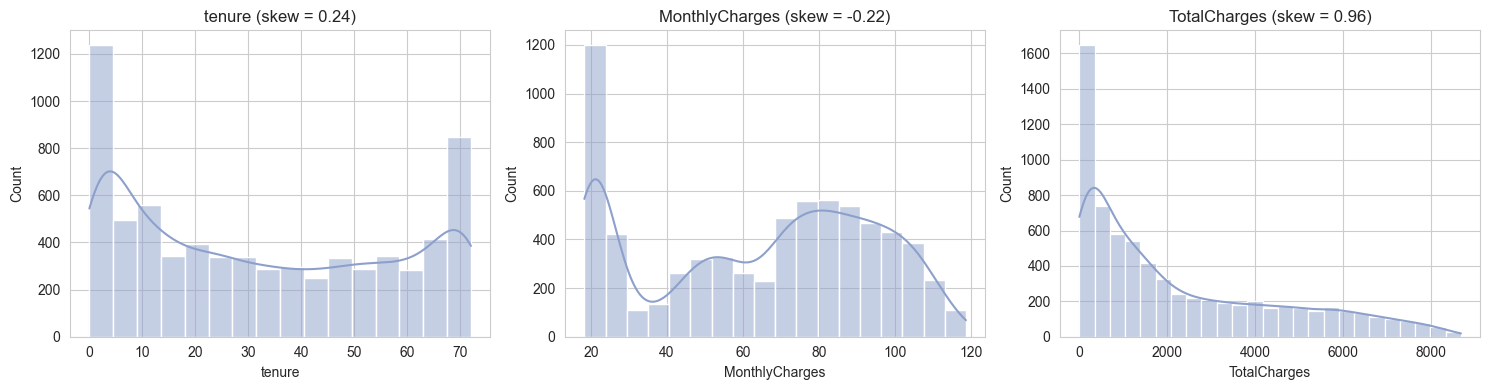

In [16]:
print(df[num_cols].skew().round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color='#8da0cb')
    ax.set_title(f'{col} (skew = {df[col].skew():.2f})')
plt.tight_layout()
plt.show()

##### Used Log-Transform to the TotalCharges

Skewness before: 0.963
Skewness after log: -0.824


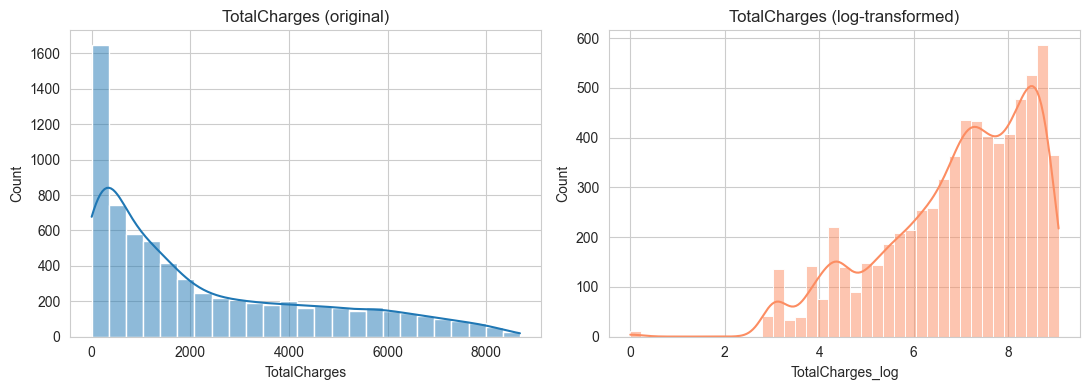

In [17]:
df['TotalCharges_log'] = np.log1p(df['TotalCharges'])   # log(1+x) handles the zeros safely

print("Skewness before:", round(df['TotalCharges'].skew(), 3))
print("Skewness after log:", round(df['TotalCharges_log'].skew(), 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['TotalCharges'], kde=True, ax=axes[0])
axes[0].set_title('TotalCharges (original)')
sns.histplot(df['TotalCharges_log'], kde=True, ax=axes[1], color='#fc8d62')
axes[1].set_title('TotalCharges (log-transformed)')
plt.tight_layout()
plt.show()

##### Feature Engineering

##### In here we created 06 new features.

###### 1. Total number of services the customer subscribes to
###### 2. Average monthly charge over the customer's lifetime
###### 3. Price change: current bill vs historical average (positive = bill has gone up)
###### 4. Tenure bands
###### 5. Has at least one protection service (security or tech support)
###### 6. Customer has no partner and no dependents

In [18]:
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

df['num_services'] = (df[service_cols] == 'Yes').sum(axis=1) + (df['InternetService'] != 'No').astype(int)

df['avg_monthly_charge'] = np.where(df['tenure'] > 0, df['TotalCharges'] / df['tenure'], df['MonthlyCharges'])

df['charge_change'] = df['MonthlyCharges'] - df['avg_monthly_charge']

df['tenure_group'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 60, 72],
                            labels=['0-1yr', '1-2yr', '2-4yr', '4-5yr', '5-6yr'])

df['has_protection'] = ((df['OnlineSecurity'] == 'Yes') | (df['TechSupport'] == 'Yes')).astype(int)

df['is_alone'] = ((df['Partner'] == 'No') & (df['Dependents'] == 'No')).astype(int)

new_features = ['num_services', 'avg_monthly_charge', 'charge_change', 'tenure_group',
                'has_protection', 'is_alone', 'TotalCharges_log']

display(df[new_features].head())

,num_services,avg_monthly_charge,charge_change,tenure_group,has_protection,is_alone,TotalCharges_log
0,2,29.850000,0.000000,0-1yr,0,0,3.429137
1,4,55.573529,1.376471,2-4yr,1,1,7.544597
2,4,54.075000,-0.225000,0-1yr,1,1,4.692723
3,4,40.905556,1.394444,2-4yr,1,1,7.518471
4,2,75.825000,-5.125000,0-1yr,0,1,5.028148


##### Checking whether the new features relate to churn

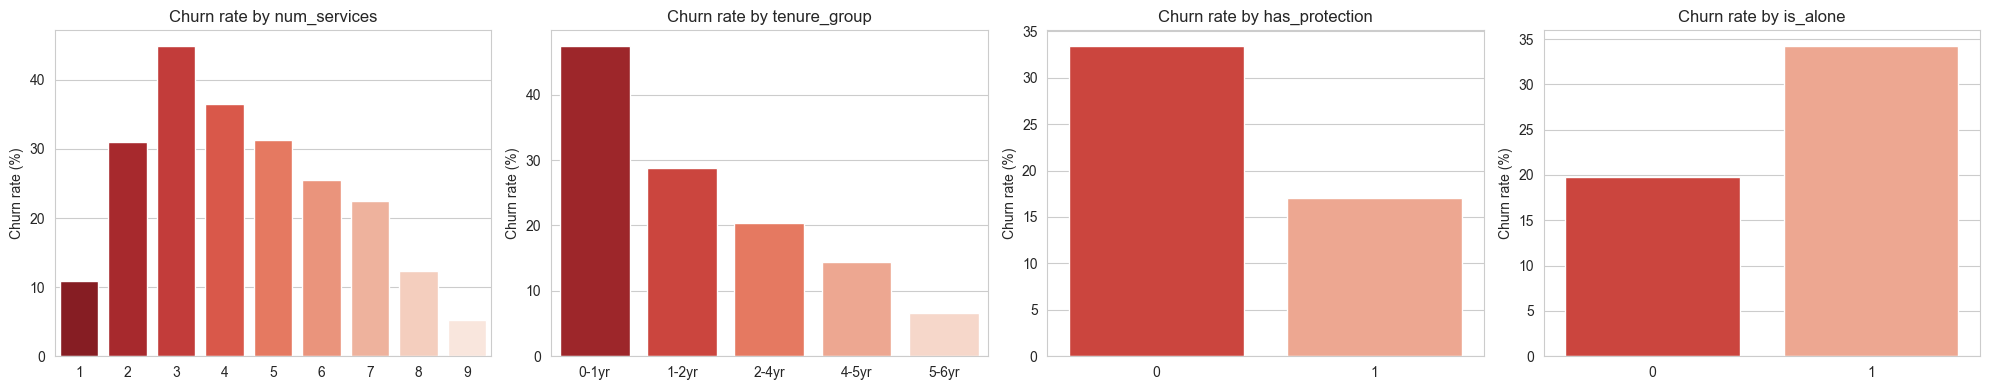

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ['num_services', 'tenure_group', 'has_protection', 'is_alone']):
    rate = df.groupby(col, observed=True)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)
    labels = rate.index.astype(str)
    sns.barplot(x=labels, y=rate.values, hue=labels, palette='Reds_r', legend=False, ax=ax)
    ax.set_title(f'Churn rate by {col}')
    ax.set_ylabel('Churn rate (%)')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

##### Encoding

In [20]:
for col in ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies']:
    df[col] = df[col].replace({'No internet service': 'No', 'No phone service': 'No'})

binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'MultipleLines',
               'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
               'StreamingTV', 'StreamingMovies', 'Churn']
for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

df['gender'] = df['gender'].map({'Male': 1, 'Female': 0})

display(df.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalCharges_log,num_services,avg_monthly_charge,charge_change,tenure_group,has_protection,is_alone
0,0,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0,3.429137,2,29.850000,0.000000,0-1yr,0,0
1,1,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0,7.544597,4,55.573529,1.376471,2-4yr,1,1
2,1,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1,4.692723,4,54.075000,-0.225000,0-1yr,1,1
3,1,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0,7.518471,4,40.905556,1.394444,2-4yr,1,1
4,0,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1,5.028148,2,75.825000,-5.125000,0-1yr,0,1


In [21]:
df['Contract'] = df['Contract'].map({'Month-to-month': 0, 'One year': 1, 'Two year': 2})
df['tenure_group'] = df['tenure_group'].cat.codes

display(df.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalCharges_log,num_services,avg_monthly_charge,charge_change,tenure_group,has_protection,is_alone
0,0,0,1,0,1,0,0,DSL,0,1,0,0,0,0,0,1,Electronic check,29.85,29.85,0,3.429137,2,29.850000,0.000000,0,0,0
1,1,0,0,0,34,1,0,DSL,1,0,1,0,0,0,1,0,Mailed check,56.95,1889.50,0,7.544597,4,55.573529,1.376471,2,1,1
2,1,0,0,0,2,1,0,DSL,1,1,0,0,0,0,0,1,Mailed check,53.85,108.15,1,4.692723,4,54.075000,-0.225000,0,1,1
3,1,0,0,0,45,0,0,DSL,1,0,1,1,0,0,1,0,Bank transfer (automatic),42.30,1840.75,0,7.518471,4,40.905556,1.394444,2,1,1
4,0,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,0,1,Electronic check,70.70,151.65,1,5.028148,2,75.825000,-5.125000,0,0,1


In [22]:
df = pd.get_dummies(df, columns=['InternetService', 'PaymentMethod'], drop_first=True, dtype=int)

# Tidy the column names
df.columns = (df.columns.str.replace(' ', '_')
                        .str.replace('(', '', regex=False)
                        .str.replace(')', '', regex=False))

print("Shape after encoding:", df.shape)
print("Non-numeric columns left:", df.select_dtypes(exclude='number').columns.tolist())
print("Missing values:", df.isna().sum().sum())

Shape after encoding: (7043, 30)
Non-numeric columns left: []
Missing values: 0


##### Use correlation matrix and understand the highly correlated pairs

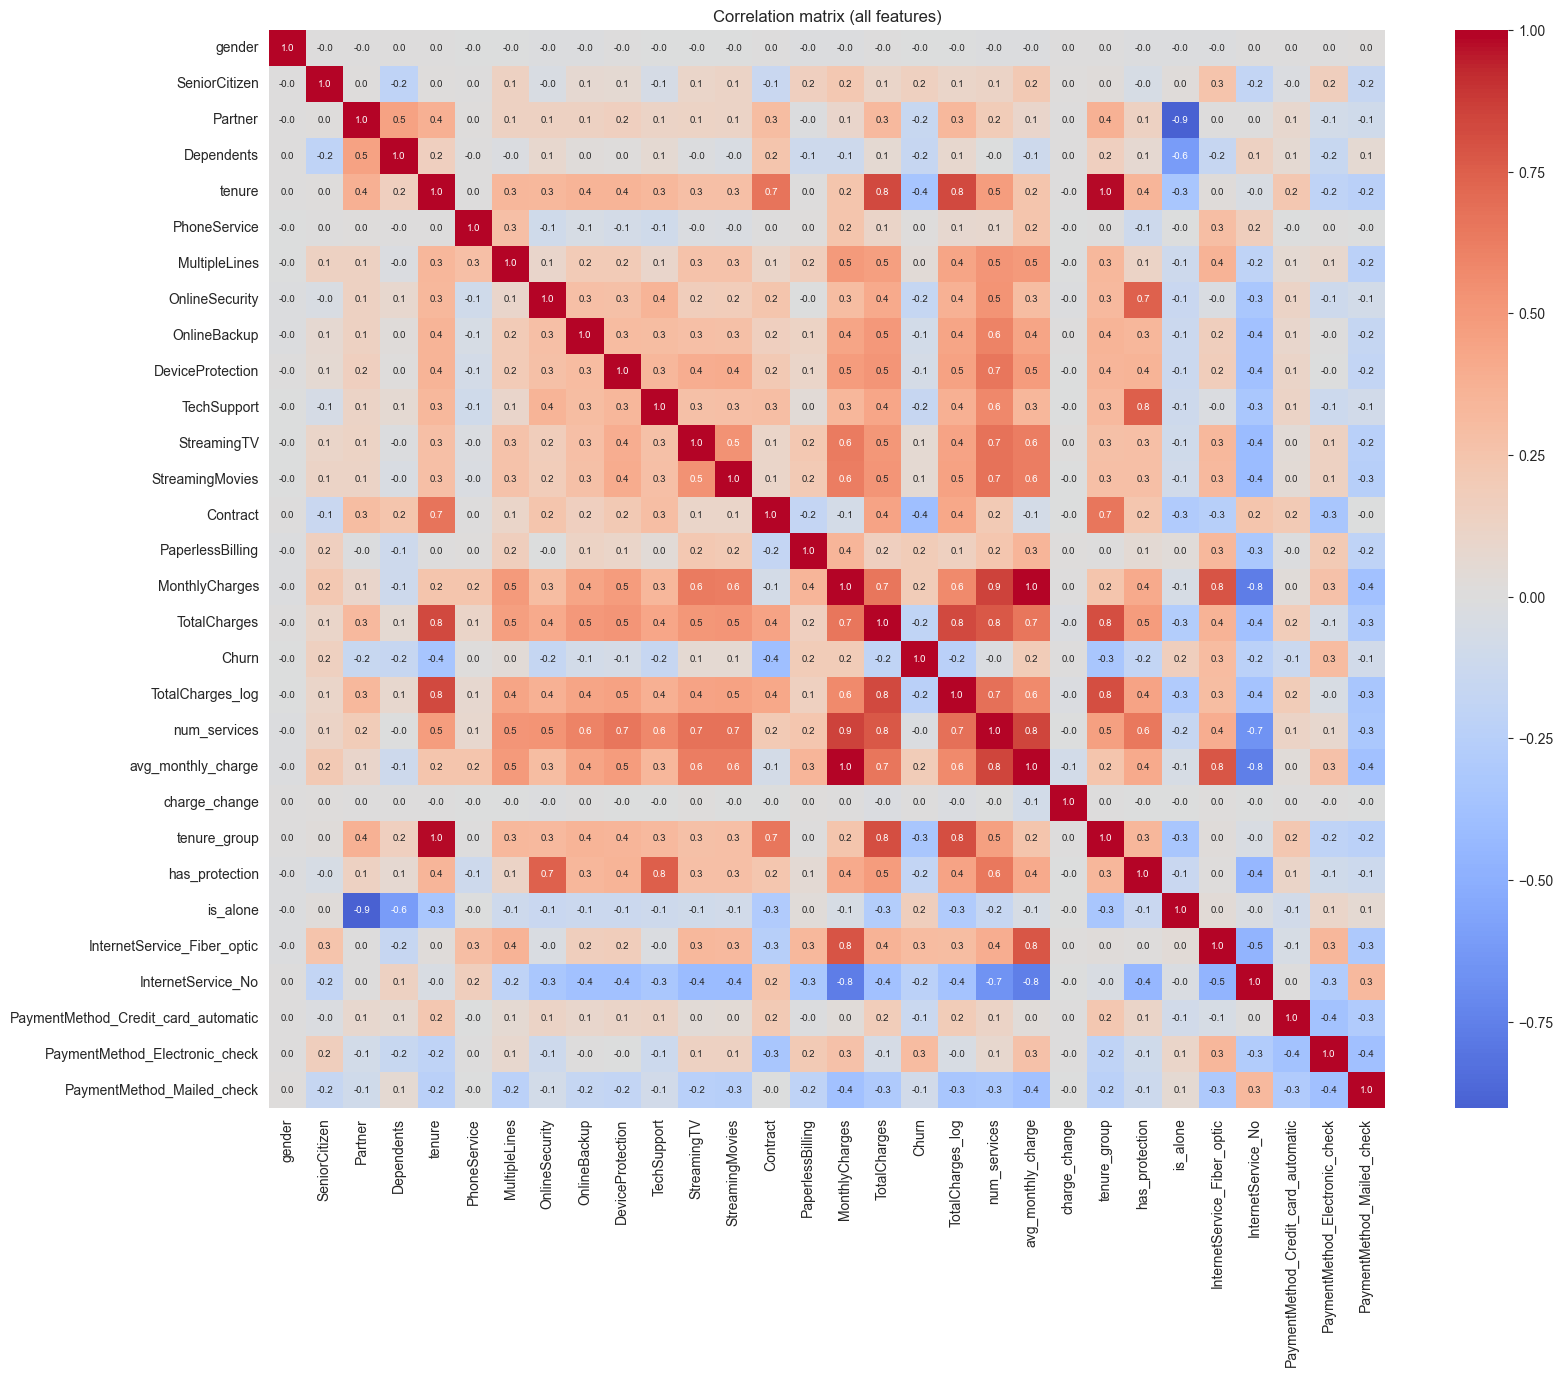

Highly correlated pairs (|r| > 0.8):
MonthlyCharges    avg_monthly_charge    0.996
tenure            tenure_group          0.981
Partner           is_alone              0.902
MonthlyCharges    num_services          0.851
num_services      avg_monthly_charge    0.849
tenure            TotalCharges_log      0.829
                  TotalCharges          0.826
TotalCharges      TotalCharges_log      0.826
                  tenure_group          0.812
TotalCharges_log  tenure_group          0.808
dtype: float64


In [23]:
plt.figure(figsize=(18, 14))
sns.heatmap(df.corr(), cmap='coolwarm', center=0, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Correlation matrix (all features)')
plt.show()

corr = df.drop(columns='Churn').corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_pairs = upper.stack().sort_values(ascending=False)
print("Highly correlated pairs (|r| > 0.8):")
print(high_pairs[high_pairs > 0.8].round(3))

##### Removing Reductant Features

##### Redundant with another feature (from Cell 12):
######   TotalCharges       -> replaced by TotalCharges_log
######   avg_monthly_charge -> r = 0.996 with MonthlyCharges
######   tenure_group       -> r = 0.981 with tenure
######   num_services       -> an exact sum of the service columns


In [24]:
redundant = ['TotalCharges', 'avg_monthly_charge', 'tenure_group', 'num_services']
X = df.drop(columns=['Churn'] + redundant)
y = df['Churn']

def vif_table(data):
    Xc = sm.add_constant(data.astype(float))
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                     index=data.columns).sort_values(ascending=False)

print(vif_table(X).round(2))

MonthlyCharges                         863.50
InternetService_Fiber_optic            148.35
InternetService_No                     104.40
PhoneService                            34.90
StreamingMovies                         24.13
StreamingTV                             24.08
TechSupport                              8.32
OnlineSecurity                           8.10
is_alone                                 7.51
MultipleLines                            7.27
DeviceProtection                         6.91
OnlineBackup                             6.75
tenure                                   6.46
TotalCharges_log                         6.20
Partner                                  6.07
has_protection                           6.03
Contract                                 2.54
PaymentMethod_Electronic_check           1.98
Dependents                               1.90
PaymentMethod_Mailed_check               1.85
PaymentMethod_Credit_card_automatic      1.56
PaperlessBilling                  

##### Spliting Data

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn ratio - train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: (5634, 25) | Test: (1409, 25)
Churn ratio - train: 0.265 | test: 0.265


In [26]:
low_info = ['gender', 'PhoneService']
X_train = X_train.drop(columns=low_info)
X_test = X_test.drop(columns=low_info)

def reduce_vif(data, threshold=10):
    data = data.copy()
    while True:
        vif = vif_table(data)
        if vif.iloc[0] <= threshold:
            return data, vif
        print(f"Dropping {vif.index[0]} (VIF = {vif.iloc[0]:.1f})")
        data = data.drop(columns=vif.index[0])

X_train, final_vif = reduce_vif(X_train)
X_test = X_test[X_train.columns] 
print(final_vif.round(2))

Dropping MonthlyCharges (VIF = 34.1)
is_alone                               7.45
tenure                                 6.28
TotalCharges_log                       6.09
Partner                                6.02
has_protection                         6.01
TechSupport                            3.23
OnlineSecurity                         3.05
InternetService_No                     2.66
Contract                               2.55
PaymentMethod_Electronic_check         1.97
Dependents                             1.88
PaymentMethod_Mailed_check             1.85
InternetService_Fiber_optic            1.85
StreamingMovies                        1.67
StreamingTV                            1.65
PaymentMethod_Credit_card_automatic    1.56
DeviceProtection                       1.50
OnlineBackup                           1.39
MultipleLines                          1.36
PaperlessBilling                       1.21
SeniorCitizen                          1.15
charge_change                          

##### Scale Data

In [27]:
cont_cols = [c for c in ['tenure', 'MonthlyCharges', 'TotalCharges_log', 'charge_change', 'Contract']
             if c in X_train.columns]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[cont_cols] = scaler.fit_transform(X_train[cont_cols])
X_test_scaled[cont_cols] = scaler.transform(X_test[cont_cols])

display(X_train_scaled[cont_cols].describe().round(2))

,tenure,TotalCharges_log,charge_change,Contract
count,5634.00,5634.00,5634.00,5634.00
mean,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00
min,-1.32,-4.44,-7.27,-0.83
25%,-0.96,-0.60,-0.45,-0.83
50%,-0.14,0.19,0.00,-0.83
75%,0.92,0.84,0.44,0.37
max,1.61,1.36,7.36,1.57


In [28]:
mm = MinMaxScaler().fit(X_train)
chi_scores, p_values = chi2_test(mm.transform(X_train), y_train)

chi_df = pd.DataFrame({'Chi2': chi_scores, 'p-value': p_values},
                      index=X_train.columns).sort_values('Chi2', ascending=False)
display(chi_df.round(4))
print("Not significant (p > 0.05):", chi_df[chi_df['p-value'] > 0.05].index.tolist())

,Chi2,p-value
Contract,448.1010,0.0000
PaymentMethod_Electronic_check,357.8805,0.0000
InternetService_Fiber_optic,308.0228,0.0000
InternetService_No,231.6462,0.0000
tenure,173.6277,0.0000
OnlineSecurity,122.2495,0.0000
Dependents,110.9083,0.0000
has_protection,109.9395,0.0000
TechSupport,109.4438,0.0000
SeniorCitizen,99.9329,0.0000


Not significant (p > 0.05): ['charge_change']


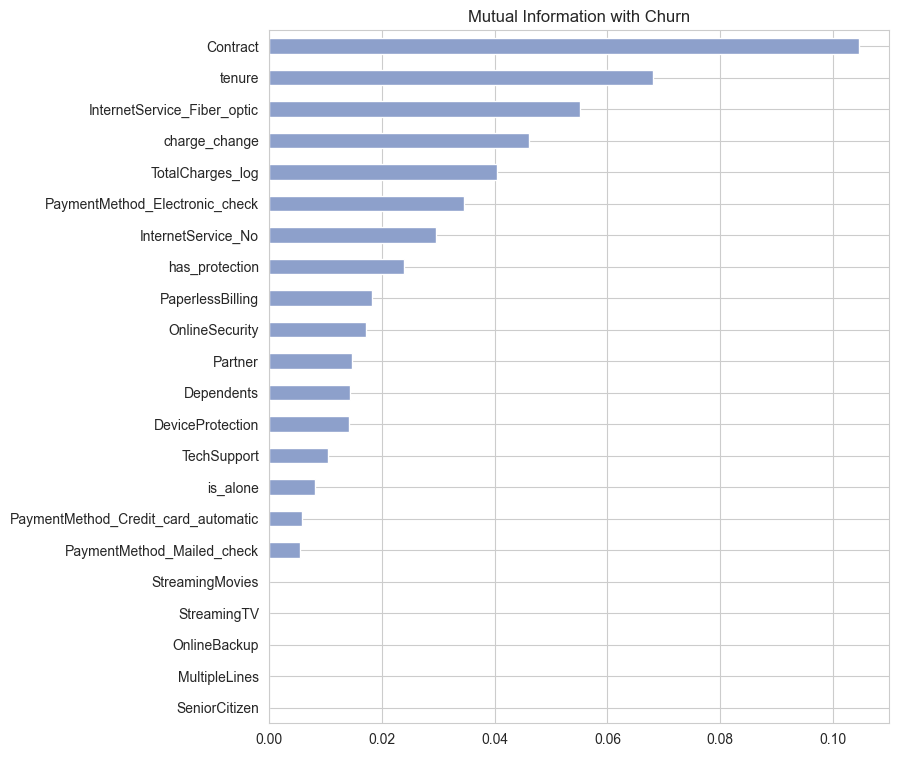

In [29]:
mi = pd.Series(mutual_info_classif(X_train_scaled, y_train, random_state=42),
               index=X_train.columns).sort_values()

plt.figure(figsize=(8, 9))
mi.plot(kind='barh', color='#8da0cb')
plt.title('Mutual Information with Churn')
plt.show()

##### Saved data separately

In [32]:
os.makedirs('Data', exist_ok=True)

X_train_scaled.to_csv('Data/X_train.csv', index=False)
X_test_scaled.to_csv('Data/X_test.csv', index=False)
y_train.to_csv('Data/y_train.csv', index=False)
y_test.to_csv('Data/y_test.csv', index=False)

joblib.dump(scaler, 'Data/scaler.pkl')

print("Saved:", os.listdir('Data'))

Saved: ['scaler.pkl', 'X_test.csv', 'X_train.csv', 'y_test.csv', 'y_train.csv']


#### The work we have done in the pre processing

##### MS26923642 - Senanayake T. K

###### Handling missing values (TotalCharges blank strings)
###### Data type conversion (TotalCharges to numeric)
###### Removing irrelevant columns (customerID)
###### Duplicate checking
###### Encoding: binary, ordinal (Contract) and one-hot
###### Train-test split (stratified)
###### Feature scaling (StandardScaler)
###### Saving processed data
######
##### MS26922652 - Sandeeptha M. N. J

###### Outlier detection
###### Log transformation (TotalCharges_log)
###### Feature engineering (new features)
###### Correlation analysis and redundant feature removal
###### Chi-square test
###### Mutual information
###### VIF / multicollinearity reduction
###### Class imbalance check